In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Declared income of the self-employed and the flat-rate regime (MEF IRPEF return statistics)
Notebook 31 counted the self-employed; this one looks at **declared income** with the Ministry of Economy and Finance (MEF) personal income tax statistics by income class, tax years 2008-2024 (files downloaded from the Department of Finance open-data portal, `data/external/source/mef_irpef/`; loader `src/cifresignificative/core/sources/mef_irpef.py`, analysis `src/cifresignificative/studies/italy_productivity/analysis/irpef.py`, table `data/processed/mef_irpef.parquet`).
**How to read the tables (this decides what can be said).** (1) The prefix of each file is the *filing* year; income refers to the *tax year = filing year - 1*, used throughout. (2) Taxpayers are classed by **reddito complessivo**, the ordinary IRPEF income. Income taxed under the flat-rate regimes (regime forfetario, regime di vantaggio, the older minimi) is taxed separately and is **not** in it, so a flat-rate filer without other income sits in the zero class whatever the size of the business: by-class distributions describe the *ordinary-regime* income, the flat-rate income exists only as counts and totals. (3) Amounts are thousand euro in the source, euro here. (4) Classes below zero are left out of means: tax year 2017 has an anomaly there and 2018 a definition change (see the checks).
**So this notebook cannot test whether declared income piles up just under the EUR 65,000 revenue threshold**: the threshold is on revenue, the classes are on a different income, and the flat-rate income is not classed. It can describe how many filers the regime has, their average net income, and how the population of ordinary-regime professionals changed. **Descriptive only, never causal.**

In [2]:
from cifresignificative.studies.italy_productivity.analysis import irpef as IR
from cifresignificative.core.sources import mef_irpef as MI
d = pd.read_parquet(PROCESSED / "mef_irpef.parquet")
print("rows:", len(d), "| tables:", d.code.nunique(), "| tax years:", d.tax_year.min(), "-", d.tax_year.max(), "| filing = tax year + 1:", bool((d.tax_year == d.filing_year - 1).all()))
cov = d.groupby("code").tax_year.agg(first="min", last="max", years="nunique"); print("coverage by table (the server returned empty files for the other years):"); display(cov)
q = MI.qa(d); ok = q[(q.suppressed == 0) & q.total.notna()]
print("class rows vs TOTALE row, cells without suppression:", len(ok), "| max |ratio-1|:", round(float((ok.class_sum_ratio - 1).abs().max()), 5), "| suppressed cells in the data:", round(float(d.suppressed.mean()) * 100, 2), "%")
p = d[d.measure.isin(["freq", "amount_keur", "mean_keur"]) & ~d.is_total].pivot_table(index=["code", "tax_year", "class_label", "variable"], columns="measure", values="value", observed=True)
p = p[(p.freq >= 1000) & p.amount_keur.notna() & p.mean_keur.notna()]; print("reported mean = amount / taxpayers (to rounding) in", round(float(((p.mean_keur - p.amount_keur / p.freq).abs() <= 0.0051).mean()) * 100, 2), "% of", len(p), "cells")
print("cross-check, taxpayers in the distribution table = taxpayers in the multi-variable table: identical in all", int(d[(d.variable == "taxpayers") & (d.measure == "freq") & (d.code != "ABPFPRO0303")].groupby(["group", "tax_year", "class_label"]).value.nunique().max() == 1) and "table pairs")
print("jump-flagged amount cells:", int(d.jump.sum()), "| by tax year:", d[d.jump].groupby("tax_year").size().to_dict())
lo = d[(d.code == "AAPFTOT0106") & (d.class_label == "minore di -1.000") & (d.measure == "freq") & (d.variable == "taxpayers")].set_index("tax_year").value
print("taxpayers with reddito complessivo below -1,000 euro:", lo.astype(int).to_dict())
b = d[(d.code == "ABPFTIT0203") & (d.variable == "Reddito d'impresa dichiarato") & (d.measure == "amount_keur") & (d.tax_year.isin([2016, 2017, 2018]))]
print("business income of VAT-number holders, EUR million, TOTALE row vs classes from zero up:"); display(pd.DataFrame({"TOTALE row": b[b.is_total].set_index("tax_year").value / 1000, "classes >= 0": b[~b.is_total & (b.class_lo >= 0)].groupby("tax_year").value.sum() / 1000}).round(0))

rows: 603551 | tables: 15 | tax years: 2008 - 2024 | filing = tax year + 1: True
coverage by table (the server returned empty files for the other years):


,first,last,years
code,,,
AAPFDIP0105,2008,2024,17
AAPFDIP0202,2008,2024,16
AAPFPEN0105,2008,2024,17
AAPFPEN0202,2008,2024,16
AAPFTOT0106,2008,2024,17
AAPFTOT0202,2008,2024,17
ABPFAGR0105,2008,2024,17
ABPFAGR0202,2011,2024,14
ABPFIMP0106,2008,2024,17


class rows vs TOTALE row, cells without suppression: 7202 | max |ratio-1|: 0.00127 | suppressed cells in the data: 3.42 %
reported mean = amount / taxpayers (to rounding) in 99.88 % of 120514 cells
cross-check, taxpayers in the distribution table = taxpayers in the multi-variable table: identical in all table pairs
jump-flagged amount cells: 140 | by tax year: {2011: 1, 2012: 4, 2014: 3, 2016: 4, 2017: 91, 2018: 1, 2019: 12, 2020: 7, 2021: 12, 2023: 5}
taxpayers with reddito complessivo below -1,000 euro: {2012: 166984, 2013: 162770, 2014: 151260, 2015: 126949, 2016: 118476, 2017: 325658, 2018: 3414, 2019: 2761, 2020: 3919, 2021: 2836, 2022: 2576, 2023: 2331, 2024: 1779}
business income of VAT-number holders, EUR million, TOTALE row vs classes from zero up:


,TOTALE row,classes >= 0
tax_year,,
2016,33964.0,35315.0
2017,20691.0,31072.0
2018,34070.0,34071.0


In [3]:
f = IR.flat_rate(d)
show = pd.DataFrame({"VAT-number holders (m)": f.tit_taxpayers / 1e6, "forfettario filers (m)": f.get("forfetario_filers") / 1e6, "forfettario net income (EUR bn)": f.get("forfetario_net_income") / 1e9, "forfettario mean net income (EUR)": f.get("forfetario_mean"),
                     "vantaggio filers (k)": f.get("vantaggio_filers") / 1e3, "minimi filers (k)": f.get("minimo_filers") / 1e3, "share of VAT-number holders in a flat regime": f.flat_share_of_tit,
                     "forfettari with ordinary income >= 1,000 EUR (share)": f.get("forfetario_with_other_income") / f.get("forfetario_filers")})
display(show.round(3).T)
mi = pd.DataFrame({g: IR.mean_income(d, g) for g in ["TOT", "DIP", "PEN", "TIT", "IMP", "PRO", "AGR"]}); med = pd.DataFrame({g: IR.median_income(d, g) for g in ["TOT", "DIP", "PEN", "TIT", "IMP", "PRO"]})
print("mean reddito complessivo per taxpayer (EUR, classes from zero up):"); display(mi.round(0).T)
print("median reddito complessivo (EUR, interpolated within the class):"); display(med.round(0).T)
tw = IR.mean_with_flat(d); print("VAT-number holders: mean reddito complessivo + flat-regime net income, per taxpayer (EUR):"); display(pd.DataFrame({"reddito complessivo only": mi.TIT, "plus flat-regime net income": tw, "employees (DIP) mean": mi.DIP, "ratio, VAT-number holders / employees": tw / mi.DIP}).round(2).T)
print("taxpayers, millions:"); display(pd.DataFrame({g: IR.taxpayers(d, g) / 1e6 for g in ["DIP", "PEN", "TIT", "IMP", "PRO", "AGR"]}).round(2).T)
print("professionals (ordinary regime): mean income from self-employment (EUR) and share with reddito complessivo >= 35,000 EUR:"); display(pd.DataFrame({"mean reddito da lavoro autonomo": IR.mean_income(d, "PRO", "Reddito da lavoro autonomo"), "share >= 35k, professionals": IR.share_at_least(d, "PRO", 35000), "share >= 35k, entrepreneurs": IR.share_at_least(d, "IMP", 35000), "share >= 35k, employees": IR.share_at_least(d, "DIP", 35000)}).round(3).T)

tax_year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
VAT-number holders (m),3.878,3.902,3.805,3.792,3.634,3.616,3.660,3.660,3.697,3.752,3.811,3.836
forfettario filers (m),NaN,NaN,0.147,0.435,0.614,0.773,1.440,1.462,1.617,1.680,1.793,1.852
forfettario net income (EUR bn),NaN,NaN,0.822,3.443,5.300,7.134,20.050,18.974,25.232,27.520,30.654,31.803
forfettario mean net income (EUR),NaN,NaN,5594.124,7909.015,8638.530,9227.288,13919.531,12977.824,15600.871,16379.514,17092.282,17174.440
vantaggio filers (k),NaN,NaN,461.276,376.630,290.424,214.218,133.745,80.460,55.402,36.053,18.186,10.605
minimi filers (k),397.876,453.593,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
share of VAT-number holders in a flat regime,0.103,0.116,0.160,0.214,0.249,0.273,0.430,0.421,0.453,0.457,0.475,0.485
"forfettari with ordinary income >= 1,000 EUR (share)",NaN,NaN,0.301,0.358,0.355,0.355,0.383,0.337,0.356,0.360,0.363,0.366


mean reddito complessivo per taxpayer (EUR, classes from zero up):


tax_year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
TOT,19481.0,19933.0,20218.0,20554.0,20742.0,20850.0,21272.0,21302.0,21011.0,21989.0,23089.0,24143.0,25127.0
DIP,22092.0,22496.0,22646.0,NaN,22957.0,22815.0,23123.0,23323.0,22982.0,23871.0,24783.0,25773.0,26728.0
PEN,18689.0,19327.0,19912.0,NaN,20545.0,20856.0,21467.0,21845.0,22101.0,22704.0,23727.0,25404.0,26744.0
TIT,NaN,25883.0,25781.0,26286.0,26163.0,27124.0,27154.0,24079.0,22578.0,25275.0,27441.0,27851.0,28359.0
IMP,NaN,21857.0,22444.0,24387.0,25692.0,26830.0,25530.0,28239.0,26003.0,30799.0,31768.0,35541.0,34533.0
PRO,NaN,49785.0,49788.0,53460.0,58298.0,60783.0,64377.0,77240.0,76864.0,86390.0,91927.0,96775.0,99066.0
AGR,NaN,13120.0,13320.0,13702.0,14145.0,16655.0,16019.0,17251.0,17046.0,16841.0,17838.0,18941.0,21262.0


median reddito complessivo (EUR, interpolated within the class):


,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
TOT,15612.0,16126.0,16346.0,16566.0,16763.0,16708.0,17209.0,17362.0,17024.0,17816.0,18757.0,20038.0,21110.0
DIP,18628.0,19294.0,19344.0,19558.0,19686.0,19460.0,19728.0,19985.0,19328.0,20247.0,20982.0,22066.0,23069.0
PEN,14719.0,15525.0,16063.0,16285.0,16558.0,16765.0,17337.0,17884.0,18178.0,18577.0,19316.0,20975.0,22265.0
TIT,NaN,14654.0,14583.0,14854.0,14341.0,13014.0,14758.0,10284.0,7259.0,8335.0,9491.0,9558.0,9831.0
IMP,NaN,14891.0,15348.0,16758.0,17372.0,15526.0,18536.0,18958.0,16409.0,19102.0,21116.0,22244.0,23827.0
PRO,NaN,32185.0,31942.0,34898.0,39182.0,41443.0,44627.0,54530.0,57198.0,64602.0,68769.0,72331.0,75203.0


VAT-number holders: mean reddito complessivo + flat-regime net income, per taxpayer (EUR):


tax_year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
reddito complessivo only,NaN,25882.68,25781.14,26286.24,26162.93,27123.61,27153.71,24079.05,22577.94,25274.99,27441.33,27851.01,28359.34
plus flat-regime net income,NaN,26904.01,26916.98,27747.47,28193.88,29664.58,29850.57,30035.56,28032.51,32322.85,34920.53,35969.61,36694.17
employees (DIP) mean,22092.23,22496.34,22646.11,NaN,22957.16,22815.39,23123.40,23323.09,22981.74,23871.24,24782.58,25773.29,26727.68
"ratio, VAT-number holders / employees",NaN,1.20,1.19,NaN,1.23,1.30,1.29,1.29,1.22,1.35,1.41,1.40,1.37


taxpayers, millions:


tax_year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
DIP,20.78,20.45,20.45,20.87,21.18,21.80,22.22,22.46,22.17,22.63,23.30,23.80,24.15
PEN,15.12,14.96,14.79,14.77,14.62,14.49,14.44,14.48,14.54,14.53,14.56,14.53,14.56
TIT,NaN,3.72,3.76,3.69,3.68,3.37,3.61,3.66,3.65,3.69,3.75,3.81,3.83
IMP,NaN,1.89,1.85,1.67,1.56,1.34,1.51,1.23,1.18,1.15,1.14,1.12,1.08
PRO,NaN,0.94,0.94,0.87,0.78,0.76,0.74,0.47,0.52,0.52,0.53,0.53,0.53
AGR,NaN,0.41,0.40,0.41,0.40,0.25,0.25,0.23,0.23,0.23,0.23,0.22,0.22


professionals (ordinary regime): mean income from self-employment (EUR) and share with reddito complessivo >= 35,000 EUR:


tax_year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mean reddito da lavoro autonomo,NaN,34949.111,34790.529,37471.493,40812.038,42475.385,45242.424,57241.234,51281.746,58678.587,62731.009,68199.472,65456.684
"share >= 35k, professionals",NaN,0.469,0.466,0.503,0.554,0.579,0.613,0.668,0.698,0.749,0.778,0.794,0.809
"share >= 35k, entrepreneurs",NaN,0.148,0.153,0.175,0.192,0.209,0.212,0.228,0.213,0.261,0.293,0.306,0.329
"share >= 35k, employees",0.129,0.130,0.133,0.141,0.139,0.140,0.146,0.149,0.145,0.153,0.165,0.182,0.195


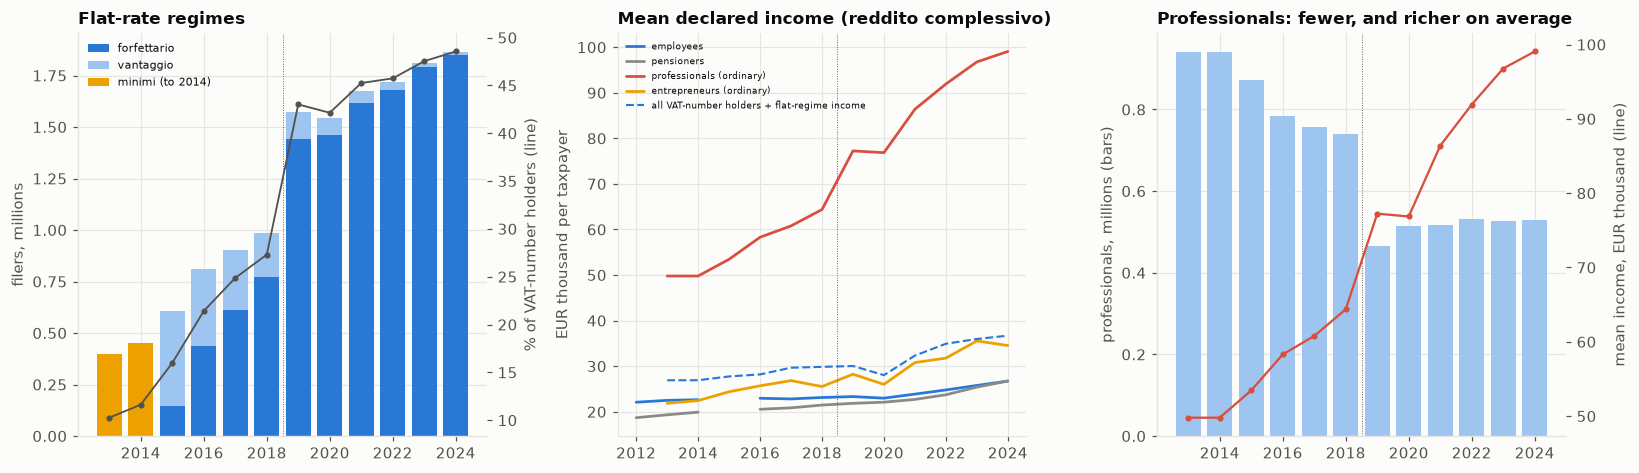

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axes[0]; ys = f.index
ax.bar(ys - 0.0, (f.get("forfetario_filers").fillna(0) / 1e6), color="#2a78d6", label="forfettario"); ax.bar(ys, f.get("vantaggio_filers").fillna(0) / 1e6, bottom=f.get("forfetario_filers").fillna(0) / 1e6, color="#9ec5f0", label="vantaggio")
ax.bar(ys, f.get("minimo_filers").fillna(0) / 1e6, color="#eda100", label="minimi (to 2014)"); ax2 = ax.twinx(); ax2.plot(ys, f.flat_share_of_tit * 100, color=INK2, marker="o", ms=3, lw=1.2); ax2.set_ylabel("% of VAT-number holders (line)"); ax2.grid(False)
ax.set_ylabel("filers, millions"); ax.set_title("Flat-rate regimes"); ax.legend(fontsize=7, loc="upper left")
ax = axes[1]
for g, c, ls in [("DIP", "#2a78d6", "-"), ("PEN", "#8a8a85", "-"), ("PRO", "#d94f3d", "-"), ("IMP", "#eda100", "-")]: ax.plot(mi.index, mi[g] / 1000, color=c, ls=ls, lw=1.8, label={"DIP": "employees", "PEN": "pensioners", "PRO": "professionals (ordinary)", "IMP": "entrepreneurs (ordinary)"}[g])
ax.plot(tw.index, tw / 1000, color="#2a78d6", ls="--", lw=1.4, label="all VAT-number holders + flat-regime income"); ax.set_ylabel("EUR thousand per taxpayer"); ax.set_title("Mean declared income (reddito complessivo)"); ax.legend(fontsize=6)
ax = axes[2]; n = IR.taxpayers(d, "PRO") / 1e6; ax.bar(n.index, n.values, color="#9ec5f0"); ax.set_ylabel("professionals, millions (bars)"); ax3 = ax.twinx(); ax3.plot(mi.index, mi.PRO / 1000, color="#d94f3d", marker="o", ms=3); ax3.set_ylabel("mean income, EUR thousand (line)"); ax3.grid(False); ax.set_title("Professionals: fewer, and richer on average")
for a in (axes[0], axes[1], axes[2]): a.axvline(2018.5, color=INK2, lw=0.6, ls=":")
fig.tight_layout(); save(fig, "32_self_employed_income")

## Costs of the professionals who stayed in the ordinary regime, by turnover band (AE tables)
New data (downloaded 2026-10-15, `data/external/source/mef_irpef_fatturato/`): the MEF tables of individuals **by prevalent income** classed by **VAT turnover**, with the items of the business-income form sections (`AE*`, `sources/mef_irpef.py`; the table codes changed in 2014 and the file for tax year 2022 is empty on the server). The regular professionals' table (form section RE) gives total fees and total expenses per turnover class, so the **cost share** (expenses / fees) can be compared with the flat-rate regime's deemed costs: for professional activities the regime taxes 78% of revenue, i.e. it assumes costs of 22% (coefficient quoted from the regime's rules, to be checked against the Agenzia delle Entrate).
**What this is and is not.** Flat-rate filers use another form section and are *not* in these tables, so this is the group that **stayed** in the ordinary regime, a selected group: if low-cost professionals move to the flat regime, the cost share of those who remain rises. The classes are on turnover (a VAT concept), coarse around the EUR 65,000 (2019-22) and 85,000 (from 2023) thresholds. Descriptive only: no bunching test and no causal reading.

tax years: [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2023, 2024] (2022 is empty on the server)
cost share = expenses / fees, regular professionals in the ordinary regime, by turnover band:


tax_year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2023,2024
band,,,,,,,,,,,,,
0-25k,0.272,0.251,0.239,0.239,0.235,0.246,0.247,0.232,0.244,0.248,0.231,0.221,0.204
25-50k,0.257,0.250,0.237,0.236,0.231,0.237,0.237,0.228,0.274,0.275,0.253,0.240,0.231
50-60k,0.269,0.268,0.256,0.254,0.248,0.248,0.246,0.236,0.287,0.282,0.262,0.245,0.236
60-75k,0.282,0.281,0.272,0.267,0.262,0.263,0.256,0.250,0.277,0.275,0.262,0.250,0.248
75-100k,0.293,0.295,0.285,0.281,0.275,0.275,0.272,0.266,0.270,0.272,0.260,0.250,0.250
100-150k,0.309,0.309,0.300,0.297,0.294,0.293,0.291,0.281,0.284,0.276,0.265,0.251,0.244
150-250k,0.401,0.402,0.396,0.392,0.388,0.387,0.382,0.367,0.371,0.356,0.339,0.300,0.275
250k+,0.471,0.481,0.477,0.469,0.463,0.461,0.459,0.453,0.460,0.449,0.434,0.396,0.371


professionals with fees (thousands):


tax_year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2023,2024
band,,,,,,,,,,,,,
0-25k,130.0,230.0,231.0,234.0,190.0,137.0,120.0,107.0,57.0,57.0,45.0,36.0,33.0
25-50k,136.0,160.0,159.0,157.0,153.0,136.0,131.0,128.0,59.0,57.0,52.0,44.0,41.0
50-60k,37.0,39.0,38.0,37.0,37.0,36.0,37.0,38.0,20.0,19.0,19.0,16.0,16.0
60-75k,40.0,42.0,41.0,40.0,41.0,40.0,41.0,42.0,28.0,27.0,27.0,24.0,22.0
75-100k,46.0,48.0,46.0,46.0,47.0,46.0,47.0,46.0,41.0,38.0,40.0,38.0,34.0
100-150k,54.0,55.0,54.0,54.0,55.0,54.0,56.0,58.0,54.0,53.0,58.0,62.0,59.0
150-250k,30.0,30.0,29.0,29.0,30.0,31.0,32.0,35.0,33.0,33.0,39.0,49.0,53.0
250k+,21.0,22.0,21.0,21.0,22.0,22.0,23.0,25.0,24.0,22.0,29.0,38.0,39.0


,change 2018 -> 2019,change 2019 -> 2024,filers 2018 -> 2019,filers 2018 -> 2024
band,,,,
0-25k,0.012,-0.040,-0.467,-0.687
25-50k,0.047,-0.043,-0.543,-0.677
50-60k,0.051,-0.051,-0.486,-0.587
60-75k,0.027,-0.029,-0.335,-0.489
75-100k,0.005,-0.020,-0.107,-0.260
100-150k,0.003,-0.040,-0.069,0.020
150-250k,0.004,-0.096,-0.055,0.542
250k+,0.007,-0.089,-0.028,0.604


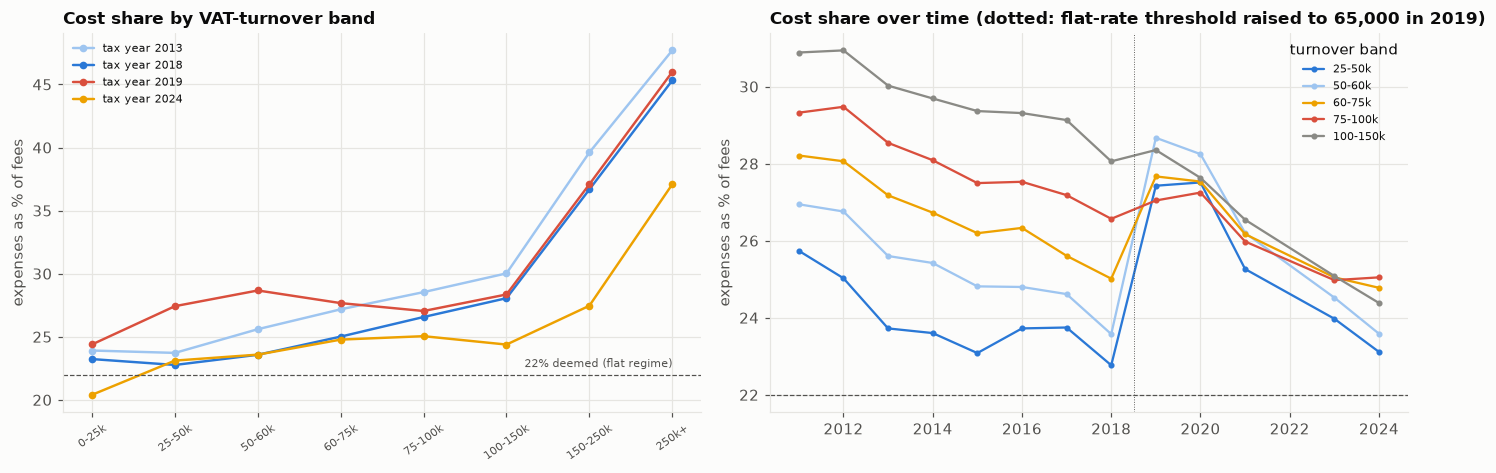

In [5]:
dims = pd.read_parquet(PROCESSED / "mef_irpef_dims.parquet")
pc = IR.professional_costs(dims)
order = pc.drop_duplicates("band").sort_values("band_order").band.tolist()
cs = pc.pivot(index="band", columns="tax_year", values="cost_share").loc[order]
fl = pc.pivot(index="band", columns="tax_year", values="filers").loc[order]
print("tax years:", [int(y) for y in sorted(pc.tax_year.unique())], "(2022 is empty on the server)")
print("cost share = expenses / fees, regular professionals in the ordinary regime, by turnover band:"); display(cs.round(3))
print("professionals with fees (thousands):"); display((fl / 1e3).round(0))
chg = (cs[2019] - cs[2018]).rename("change 2018 -> 2019"); chg2 = (cs[2024] - cs[2019]).rename("change 2019 -> 2024")
display(pd.concat([chg, chg2, (fl[2019] / fl[2018] - 1).rename("filers 2018 -> 2019"), (fl[2024] / fl[2018] - 1).rename("filers 2018 -> 2024")], axis=1).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
for y, c in [(2013, "#9ec5f0"), (2018, "#2a78d6"), (2019, "#d94f3d"), (2024, "#eda100")]: ax.plot(range(len(order)), cs[y].values * 100, marker="o", ms=4, color=c, lw=1.6, label=f"tax year {y}")
ax.axhline(22, color=INK2, lw=0.8, ls="--"); ax.text(len(order) - 1, 22.6, "22% deemed (flat regime)", ha="right", fontsize=7, color=INK2)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=35, fontsize=7); ax.set_ylabel("expenses as % of fees"); ax.set_title("Cost share by VAT-turnover band"); ax.legend(fontsize=7)
ax = axes[1]
for b, c in [("25-50k", "#2a78d6"), ("50-60k", "#9ec5f0"), ("60-75k", "#eda100"), ("75-100k", "#d94f3d"), ("100-150k", "#8a8a85")]: ax.plot(cs.columns, cs.loc[b].values * 100, marker="o", ms=3, lw=1.5, color=c, label=b)
ax.axhline(22, color=INK2, lw=0.8, ls="--"); ax.axvline(2018.5, color=INK2, lw=0.6, ls=":"); ax.set_ylabel("expenses as % of fees"); ax.set_title("Cost share over time (dotted: flat-rate threshold raised to 65,000 in 2019)"); ax.legend(fontsize=7, title="turnover band")
fig.tight_layout(); save(fig, "32_professional_costs")

## Takeaways (MEF IRPEF return statistics, tax years 2008-2024; descriptive)
- **The data are sound once read correctly.** 238 of the 315 files requested are non-empty (the server returned empty files for filing years 2005-2008, for the business-owner detail tables of 2009-2011 and for the 2016 employee and pensioner detail), giving tax years 2008-2024 for the distribution tables and 2011/2012-2024 for the detail on VAT-number holders. Where nothing is suppressed the class rows add up to the TOTALE row within 0.13%; the reported mean equals amount / taxpayers (to rounding) in 99.88% of 120,514 cells; taxpayer counts are identical in the paired tables; 3.4% of cells are suppressed (`***`). Three encodings, Italian number format and drifting variable names were normalised in the loader. The file prefix is the *filing* year: income is that of the previous year.
- **One anomaly and one definition change, both in the lowest classes.** Taxpayers with reddito complessivo below -1,000 EUR number 118,476 in tax year 2016, 325,658 in 2017 and 3,414 in 2018 (about 2-4 thousand since). In 2017 that class carries a -10.4 bn EUR business-income amount (91 cells flagged, all of tax year 2017), so the TOTALE row of business income is 20.7 bn against 31.1 bn from the classes at zero and above; a plausible cause is the 2017 switch to cash-basis accounting for simplified-regime businesses, but the files do not say. Negative classes are therefore left out of means and counts; other flagged jumps (140 cells in all) are mostly genuine regime changes (flat-rate net income by class in 2019, the 2021 integration treatment).
- **The flat-rate regimes now cover about half of the VAT-number holders.** The share of individuals with a VAT number in a flat regime rose from 10% (2013, the old minimi regime, 0.40 m) to 21% in 2016, 27% in 2018, 43% in 2019 and 48.5% in 2024, when 1.85 m filers declared 31.8 bn EUR of net income under the regime forfettario (mean 17.2 thousand EUR; 9.2 thousand in 2018, 13.9 thousand in 2019). The step is in tax year 2019: forfettario filers 0.77 m to 1.44 m (+0.67 m) while ordinary-regime professionals fell from 0.74 m to 0.47 m and entrepreneurs from 1.51 m to 1.23 m, in the year the revenue threshold was raised to EUR 65,000 (L. 145/2018). That is timing, not a causal estimate: the regime's eligibility rules changed in several ways at once. About 37% of forfettari in 2024 also report at least 1,000 EUR of ordinary income (30% in 2015, 38% in 2019), i.e. many hold another job, pension or rental income.
- **Declared income of the self-employed, depending on what is counted.** Individuals with a VAT number declare on average 36.7 thousand EUR in 2024 once the flat-regime net income is added (28.4 thousand on reddito complessivo alone), against 26.7 thousand for employees: ratios of 1.37 and 1.06, and 1.20 in 2013 (26.9 vs 22.5 thousand). Their *median* reddito complessivo falls from 14.7 thousand (2013) to 9.8 thousand (2024) because flat-regime filers sit near zero: that is a classification effect, not falling income (employees' median rose from 19.3 to 23.1 thousand).
- **The ordinary-regime professionals became fewer and richer, which is mostly selection.** Professionals fell from 0.94 m (2013) to 0.53 m (2024) while their mean income from self-employment rose from 34.9 to 65.5 thousand EUR and the share with reddito complessivo of at least 35,000 EUR from 47% to 81% (employees: 13% to 19.5%; entrepreneurs: 15% to 33%). The largest step coincides with the flat-regime step of 2019 (0.74 m to 0.47 m professionals, mean 45.2 to 57.2 thousand). The data cannot separate selection from growth.
- **Costs of the professionals who stayed in the ordinary regime (AE tables, turnover bands).** Expenses are 23-27% of fees below EUR 150,000 of turnover in 2018, 37% at 150-250 thousand and 45% above 250 thousand; the flat regime assumes 22% for professional activities (rule quoted, unchecked). In 2019, when the flat-regime threshold went to EUR 65,000, the number of ordinary-regime professionals fell by 47% (0-25 thousand), 54% (25-50 thousand) and 49% (50-60 thousand), against 3-7% above 100 thousand; the cost share of those who remained rose by 4.7 pp (25-50 thousand: 22.8% to 27.4%) and 5.1 pp (50-60 thousand) against 0.3-0.7 pp above 100 thousand. That pattern is what selection would produce (low-cost filers leave, high-cost ones stay); it is not a measure of anyone's true costs, and flat-rate filers are not in these tables. Since 2019 the shares have fallen back in every band (25-50 thousand: 27.4% in 2019, 23.1% in 2024; above 250 thousand: 46.0% to 37.1%). Tax year 2022 is empty on the server; the entrepreneurs' tables (sections RF and RG) are loaded but not analysed.
- **What cannot be done with these tables.** (1) No bunching test at the EUR 65,000 threshold: the threshold is on revenue, the classes are on reddito complessivo, flat-regime income is not classed (63% of forfettari sit in the zero and 0-1,000 EUR classes), and the classes are coarse anyway. That test needs revenue-level administrative data (Agenzia delle Entrate). (2) No distribution of flat-regime income by class, only counts, totals and means. (3) No link to individuals' other attributes (sector, age, region, which are available in other portal tables not downloaded here).
- **Limits.** Tax year 2015 lacks the employee and pensioner detail (empty server files), 2009-2011 the VAT-number detail; small cells are suppressed; amounts are declared, not true, income (the tax-gap evidence in notebook 09 applies); class medians are interpolated within wide classes; the flat-regime counts for 2015 (the first year) are partly suppressed in the TOTALE row, so they are summed from the classes.
